# Experiment: Gesture Classification with Deep Learning

In this experiment, a neural network model is trained with EMG data from the 65HDsEMG database to classify gestures. Here, a subset of the EMG channels is used to have the configuration/organization of that of the armband developed for this project. The data are divided into training and validation data to train the model, and into test data to evaluate the classification performance of the trained model.

# Signal preprocessing

The folowing 4-step preprocessing is applied to the EMG signal data:
1. Rectification
2. Teager-Kaiser Energy Operator (TKE)
3. Moving Average (30 samples)
4. Normalization

The normalization step is applied during the training while the other ones have already been applied to the data. 

## Table of Contents

- [0. Import libraries](#0)
- [1. Config Variables and hyperparameters](#1)
- [2. Load dataset with dataloader](#2)
- [3. Create model to train](#3)
- [4. Training](#4)
- [5. Evaluate best model](#5)
- [6. Save the model in .H5 file](#6)


<a name="0"></a>
# Import Libraries

In [1]:
import os, sys

processing_source_path = os.path.abspath('./../../../Processing/')
if(processing_source_path not in sys.path):
    sys.path.append(processing_source_path)
import ProcessingPipeline as pp

dataloader_source_path = os.path.abspath('./../../../Dataloader/')
if(dataloader_source_path not in sys.path):
    sys.path.append(dataloader_source_path)
from EMGGestureDataGen import EMGGestureDataGen

dataloader_source_path = os.path.abspath('./../../../Dataloader/')
if(dataloader_source_path not in sys.path):
    sys.path.append(dataloader_source_path)
from EMGGestureDataGen import EMGGestureDataGen
from KerasDataPipeline import KerasDataPipeline

model_source_path = os.path.abspath('./../../../Keras_deep_models/')
if(model_source_path not in sys.path):
    sys.path.append(model_source_path)
from EMGConv2DResNetModel import EMGConv2DResNetModel

dataloader_source_path = os.path.abspath('./../../../Utils/')
if(dataloader_source_path not in sys.path):
    sys.path.append(dataloader_source_path)
import utils as utils
import available_metrics as metrics

In [2]:
'''
bpmll
seaborn
'''

'\nbpmll\nseaborn\n'

In [3]:
import numpy as np
from os.path import join
import datetime
import matplotlib.pyplot as plt
import pandas as pd
import json

In [4]:
import tensorflow as tf
print(tf.__version__)
gpus = tf.config.list_physical_devices('GPU')
if gpus:
  try:
    # Currently, memory growth needs to be the same across GPUs
    for gpu in gpus:
      tf.config.experimental.set_memory_growth(gpu, True)
    logical_gpus = tf.config.list_logical_devices('GPU')
    print(len(gpus), "Physical GPUs,", len(logical_gpus), "Logical GPUs")
  except RuntimeError as e:
    # Memory growth must be set before GPUs have been initialized
    print(e)

2.9.1
8 Physical GPUs, 8 Logical GPUs


2026-08-31 20:40:06.268984: I tensorflow/core/platform/cpu_feature_guard.cc:194] This TensorFlow binary is optimized with oneAPI Deep Neural Network Library (oneDNN) to use the following CPU instructions in performance-critical operations:  SSE3 SSE4.1 SSE4.2 AVX
To enable them in other operations, rebuild TensorFlow with the appropriate compiler flags.
2026-08-31 20:40:12.146182: I tensorflow/core/common_runtime/gpu/gpu_process_state.cc:222] Using CUDA malloc Async allocator for GPU: 0
2026-08-31 20:40:12.146464: I tensorflow/core/common_runtime/gpu/gpu_device.cc:1532] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 51763 MB memory:  -> device: 0, name: NVIDIA A100-SXM4-80GB, pci bus id: 0000:07:00.0, compute capability: 8.0
2026-08-31 20:40:12.151613: I tensorflow/core/common_runtime/gpu/gpu_process_state.cc:222] Using CUDA malloc Async allocator for GPU: 1
2026-08-31 20:40:12.151682: I tensorflow/core/common_runtime/gpu/gpu_device.cc:1532] Created device /job:localh

<a name="1"></a>
# Config Variables and hyperparameters

In [5]:
# model_name = 'EMG65_2D_CNN_multiclass_armband_onesubject20230627_194533'
model_name = None

In [6]:
def _cbeb_data_root():
    """Processed and raw datasets live in <package>/data, or CBEB_DATA_ROOT."""
    import os
    from pathlib import Path
    env = os.environ.get("CBEB_DATA_ROOT")
    if env:
        return Path(env).resolve()
    pkg = Path.cwd().resolve()
    for _ in range(8):
        if (pkg / "README.md").exists() and (pkg / "EMG").exists():
            return (pkg / "data").resolve()
        if pkg.parent == pkg:
            break
        pkg = pkg.parent
    return (Path.cwd().resolve() / "data").resolve()

if model_name is None:
    print('Crate new config model')
    data_params = {
        "checkpoint_path": "trainings/",
        "database_path": "65HD_gestures_common", #"65HD_gestures_comparison2_balanced",
        "training_name": 'EMG65_2D_CNN_multiclass_armband' + datetime.datetime.now().strftime("%Y%m%d_%H%M%S"),
        "img_width": 16,
        "img_height": 8,
        "num_features": 256, #num_samples
        "window_step": 12,
        'armband': False,
        'norm':2, # by channels, each channel belong the time
    }
    training_params = {
        "early_stopping_patient": 10,
        "epochs": 200,
        "batch_size": 256,
        "lr": 0.01,
        #"loss": 'CatCE',
        "loss": 'SparceCatCE',
        "filter_divisor": 4,
    }
    optimizer = tf.optimizers.SGD(learning_rate=0.01, momentum=0.9, nesterov=True)
    model_params = {
        "model_output_mode": 'multiclass',
        "print_model": True,
        #"network_name": 'EMG_65HDsEMG_2D_CNN_128f_128ch_SCE_normminmax_bychannel_SGD',
        #"optimizer": optimizer._name,
        "network_name": 'EMG_65HDsEMG_2D_CNN_128f_128ch_SCE_normminmax_bychannel_adamW',
        "optimizer": 'adamW',
        "channels": 128,
    }
    # Combine all categories into a single dictionary
    config_model = {**data_params, **model_params, **training_params}
    
    try:
        with open(join(str(_cbeb_data_root() / config_model['database_path']), 'train', 'dataset_param.json')) as json_file:
            dataset_param = json.load(json_file)
            config_model['num_classes'] = len(dataset_param['dataset']['gestures'])
    except:
         config_model['num_classes'] = 7
else:
    config_path = join('trainings/', model_name, 'training_param.json')
    print('Loading config model from:', config_path)
    with open(config_path) as json_file:
        config_model = json.load(json_file)
    
print(config_model)


Crate new config model
{'checkpoint_path': 'trainings/', 'database_path': '65HD_gestures_common', 'training_name': 'EMG65_2D_CNN_multiclass_armband20260831_204013', 'img_width': 16, 'img_height': 8, 'num_features': 256, 'window_step': 12, 'armband': False, 'norm': 2, 'model_output_mode': 'multiclass', 'print_model': True, 'network_name': 'EMG_65HDsEMG_2D_CNN_128f_128ch_SCE_normminmax_bychannel_adamW', 'optimizer': 'adamW', 'channels': 128, 'early_stopping_patient': 10, 'epochs': 200, 'batch_size': 256, 'lr': 0.01, 'loss': 'SparceCatCE', 'filter_divisor': 4, 'num_classes': 7}


In [7]:
# Data root: download raw/preprocessed data under <package>/data (see docs/DATASETS.md)
# or export CBEB_DATA_ROOT=/path/to/data
from pathlib import Path as _Path
import os as _os
_pkg = _Path.cwd().resolve()
for _ in range(8):
    if (_pkg / "README.md").exists() and (_pkg / "EMG").exists():
        break
    _pkg = _pkg.parent
_DATA_ROOT = _Path(_os.environ.get("CBEB_DATA_ROOT", _pkg / "data")).resolve()
dataset_path = str(_DATA_ROOT / config_model["database_path"])
num_gestures = config_model['num_classes']
window_size = config_model['num_features']
window_step = config_model['window_step']
img_width = config_model['img_width']
img_height = config_model['img_height']
batch_size = config_model['batch_size']
num_emg_channels = config_model['channels']
armband= config_model['armband']


In [8]:
try:
    with open(join(dataset_path, 'train', 'dataset_param.json')) as json_file:
        dataset_param = json.load(json_file)
        gesture_list = dataset_param['dataset']['gestures']
        print(dataset_param)
except:
    #gesture_list =[0, 13, 14, 17, 20, 36, 58, 59, 63, 64]
    with open('../../../DataBase_Treatment/gestures_comparison_65HD_Hyser.json', 'r', encoding='utf-8') as f:
        gestures = json.load(f)
    gesture_names = [g['hdemg_label'] for g in gestures['gesture_mapping']]
    gesture_list = [int(g['hdemg_id']) for g in gestures['gesture_mapping']]
    print(gesture_names)
    #print(glob.glob(join(dataset_path, 'train/*')))
gesture_list, len(gesture_list)

{'name': '65HDsEMG_20260831_190813', 'dataset': {'name': '65HDsEMG', 'preprocessing': ['SampleTrimmer(1,1024,1024)', 'Retification', 'EMGTKE', 'MAFilter(31)'], 'force_preprocessing': ['SampleTrimmer(1,1055,1025)'], 'subject': ['25312382', '25313324', 'test', '25313078', '25309355', '25295423', '25323215', 'unique', '25323257', '.ipynb_checkpoints', '25323134', '25296788', '24350114', '25296644', '25323104', '25313597', '25323065', '25313726', '25312253', '25295225'], 'session': [0], 'gestures': [0, 10, 8, 6, 4, 2, 13, 14, 15, 16, 61, 58], 'repetition': [1, 3, 5], 'rest_repetition': 3}}


([0, 10, 8, 6, 4, 2, 13, 14, 15, 16, 61, 58], 12)

In [9]:
config_model['gesture_list'] = gesture_list
config_model['num_classes'] = len(gesture_list)

<a name="2"></a>
# Load dataset with dataloader

In [10]:
num_emg_channels

128

In [11]:
data_processing = pp.ProcessingPipeline([
    pp.NormMinMax(axis=config_model['norm']), # initial shape: (batchsize, img_width*img_height, samples)
    pp.DataReshape((img_width, img_height, window_size)),
    #pp.LabelOneHot(np.sort(gesture_list)) # to multiclass 
    ])

train_dataset = EMGGestureDataGen(join(dataset_path, 'train/'), batch_size, window_size, window_step, num_emg_channels, processing=data_processing, armband=armband, dataset_name=config_model['database_path'])
val_dataset = EMGGestureDataGen(join(dataset_path, 'val/'), batch_size, window_size, window_step, num_emg_channels, processing=data_processing, armband=armband, dataset_name=config_model['database_path'])
test_dataset = EMGGestureDataGen(join(dataset_path, 'test/'), batch_size, window_size, window_step, num_emg_channels, processing=data_processing, armband=armband, dataset_name=config_model['database_path'])

In [12]:
from os import listdir
from os.path import isfile, join

folder_path=join(dataset_path, 'train/')
files = [f for f in listdir(folder_path) if (isfile(join(folder_path, f)) and ".hdf5" in f)]

In [13]:
files

['25323215.hdf5',
 '25313597.hdf5',
 '25323065.hdf5',
 '25309355.hdf5',
 '25296644.hdf5',
 '25295225.hdf5',
 '25312253.hdf5',
 '25312382.hdf5',
 '25296788.hdf5',
 '25323134.hdf5',
 '25313078.hdf5',
 '25323257.hdf5',
 '25313726.hdf5',
 '25313324.hdf5',
 '24350114.hdf5',
 '25323104.hdf5',
 '25295423.hdf5']

In [14]:
test_dataset.yData[0]

0

In [15]:
train_dataset[0][0].shape

(256, 16, 8, 256)

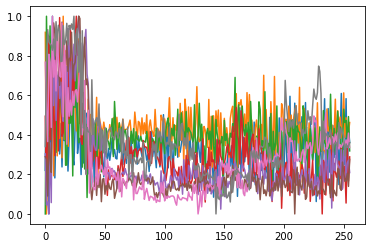

In [16]:
plt.plot(train_dataset[0][0][0,0,:].T)
plt.show()

In [17]:
# # UNCOMMENT TO USE CLASS WEIGHTS
# from sklearn.utils import class_weight

# class_weights = class_weight.compute_class_weight('balanced', classes=np.arange(len(gesture_list)), y=train_dataset.yData)
# config_model['class_weights'] = dict(enumerate(class_weights))

In [18]:
#train_dataset_pipeline = KerasDataPipeline(train_dataset, (None, img_width, img_height, window_size), [None, config_model['num_classes']])
#val_dataset_pipeline = KerasDataPipeline(val_dataset, (None, img_width, img_height, window_size), [None, config_model['num_classes']])

train_dataset_pipeline = KerasDataPipeline(train_dataset, (None, img_width, img_height, window_size), [None, ])
val_dataset_pipeline = KerasDataPipeline(val_dataset, (None, img_width, img_height, window_size), [None, ])

In [19]:
val_dataset_pipeline.outputShape


[None]

<a name="3"></a>
# Create model to train

In [20]:
'''# Ver desbalanceamento
unique, counts = np.unique(train_dataset.yData, return_counts=True)
print(dict(zip(unique, counts)))
class_weights = class_weight.compute_class_weight(
    'balanced',
    classes=np.arange(len(gesture_list)),
    y=train_dataset.yData
)
config_model['class_weights'] = dict(enumerate(class_weights))'''

"# Ver desbalanceamento\nunique, counts = np.unique(train_dataset.yData, return_counts=True)\nprint(dict(zip(unique, counts)))\nclass_weights = class_weight.compute_class_weight(\n    'balanced',\n    classes=np.arange(len(gesture_list)),\n    y=train_dataset.yData\n)\nconfig_model['class_weights'] = dict(enumerate(class_weights))"

In [21]:
config_model

{'checkpoint_path': 'trainings/',
 'database_path': '65HD_gestures_common',
 'training_name': 'EMG65_2D_CNN_multiclass_armband20260831_204013',
 'img_width': 16,
 'img_height': 8,
 'num_features': 256,
 'window_step': 12,
 'armband': False,
 'norm': 2,
 'model_output_mode': 'multiclass',
 'print_model': True,
 'network_name': 'EMG_65HDsEMG_2D_CNN_128f_128ch_SCE_normminmax_bychannel_adamW',
 'optimizer': 'adamW',
 'channels': 128,
 'early_stopping_patient': 10,
 'epochs': 200,
 'batch_size': 256,
 'lr': 0.01,
 'loss': 'SparceCatCE',
 'filter_divisor': 4,
 'num_classes': 12,
 'gesture_list': [0, 10, 8, 6, 4, 2, 13, 14, 15, 16, 61, 58]}

In [22]:
emg_model = EMGConv2DResNetModel(config_model)
emg_model.load_model()

path False
model compiled
Model: "model"
__________________________________________________________________________________________________
 Layer (type)                   Output Shape         Param #     Connected to                     
 input_1 (InputLayer)           [(None, 16, 8, 256)  0           []                               
                                ]                                                                 
                                                                                                  
 conv2d (Conv2D)                (None, 16, 8, 32)    73760       ['input_1[0][0]']                
                                                                                                  
 batch_normalization (BatchNorm  (None, 16, 8, 32)   128         ['conv2d[0][0]']                 
 alization)                                                                                       
                                                                    

<a name="4"></a>
# Training

In [23]:
history = emg_model.train(train_dataset_pipeline.datasetPipeline, val_dataset_pipeline.datasetPipeline)

with open(join(config_model['checkpoint_path'], config_model['network_name'], 'training_param.json'), 'w') as fp:
    json.dump(config_model, fp, indent=4)

no weights
trainings/EMG_65HDsEMG_2D_CNN_128f_128ch_SCE_normminmax_bychannel_adamW
Epoch 1/200


2026-08-31 20:41:47.048588: I tensorflow/stream_executor/cuda/cuda_dnn.cc:424] Loaded cuDNN version 8500
2026-08-31 20:41:50.685579: I tensorflow/stream_executor/cuda/cuda_blas.cc:1804] TensorFloat-32 will be used for the matrix multiplication. This will only be logged once.


INFO:tensorflow:Assets written to: trainings/EMG_65HDsEMG_2D_CNN_128f_128ch_SCE_normminmax_bychannel_adamW/assets


INFO:tensorflow:Assets written to: trainings/EMG_65HDsEMG_2D_CNN_128f_128ch_SCE_normminmax_bychannel_adamW/assets


1869/1869 - 321s - loss: 1.5011 - accuracy: 0.4939 - val_loss: 1.4555 - val_accuracy: 0.5261 - 321s/epoch - 171ms/step
Epoch 2/200


INFO:tensorflow:Assets written to: trainings/EMG_65HDsEMG_2D_CNN_128f_128ch_SCE_normminmax_bychannel_adamW/assets


... (22 outputs left out)

1869/1869 - 254s - loss: 0.5008 - accuracy: 0.8386 - val_loss: 0.3152 - val_accuracy: 0.9078 - 254s/epoch - 136ms/step
Epoch 22/200
1869/1869 - 252s - loss: 0.4969 - accuracy: 0.8410 - val_loss: 0.5674 - val_accuracy: 0.8354 - 252s/epoch - 135ms/step
Epoch 23/200
1869/1869 - 254s - loss: 0.4915 - accuracy: 0.8421 - val_loss: 0.4179 - val_accuracy: 0.8763 - 254s/epoch - 136ms/step
Epoch 24/200
1869/1869 - 250s - loss: 0.4875 - accuracy: 0.8431 - val_loss: 0.3269 - val_accuracy: 0.9046 - 250s/epoch - 134ms/step
Epoch 25/200
1869/1869 - 250s - loss: 0.4827 - accuracy: 0.8449 - val_loss: 0.3329 - val_accuracy: 0.9001 - 250s/epoch - 134ms/step
Epoch 26/200
1869/1869 - 241s - loss: 0.4800 - accuracy: 0.8458 - val_loss: 1.1575 - val_accuracy: 0.6591 - 241s/epoch - 129ms/step
Epoch 27/200


INFO:tensorflow:Assets written to: trainings/EMG_65HDsEMG_2D_CNN_128f_128ch_SCE_normminmax_bychannel_adamW/assets


INFO:tensorflow:Assets written to: trainings/EMG_65HDsEMG_2D_CNN_128f_128ch_SCE_normminmax_bychannel_adamW/assets


1869/1869 - 252s - loss: 0.4755 - accuracy: 0.8473 - val_loss: 0.3113 - val_accuracy: 0.9095 - 252s/epoch - 135ms/step
Epoch 28/200
1869/1869 - 240s - loss: 0.4742 - accuracy: 0.8482 - val_loss: 0.3656 - val_accuracy: 0.8933 - 240s/epoch - 128ms/step
Epoch 29/200
1869/1869 - 248s - loss: 0.4709 - accuracy: 0.8486 - val_loss: 0.4576 - val_accuracy: 0.8606 - 248s/epoch - 133ms/step
Epoch 30/200
1869/1869 - 232s - loss: 0.4668 - accuracy: 0.8504 - val_loss: 0.9047 - val_accuracy: 0.7263 - 232s/epoch - 124ms/step
Epoch 31/200
1869/1869 - 227s - loss: 0.4649 - accuracy: 0.8508 - val_loss: 0.3182 - val_accuracy: 0.9061 - 227s/epoch - 122ms/step
Epoch 32/200
1869/1869 - 214s - loss: 0.4621 - accuracy: 0.8522 - val_loss: 0.3928 - val_accuracy: 0.8846 - 214s/epoch - 114ms/step
Epoch 33/200
1869/1869 - 206s - loss: 0.4578 - accuracy: 0.8529 - val_loss: 0.5282 - val_accuracy: 0.8436 - 206s/epoch - 110ms/step
Epoch 34/200
1869/1869 - 205s - loss: 0.4578 - accuracy: 0.8531 - val_loss: 0.3660 - val_

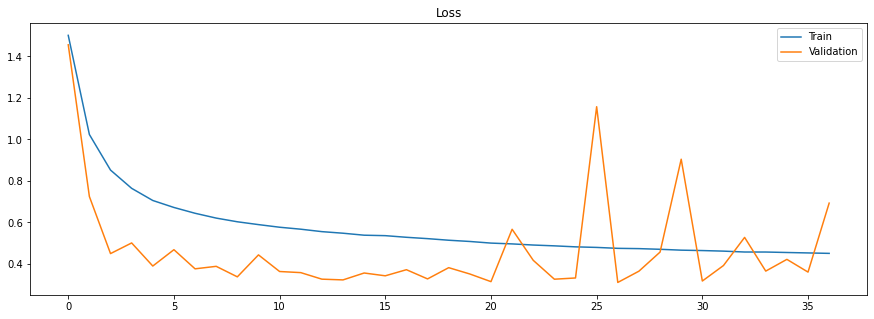

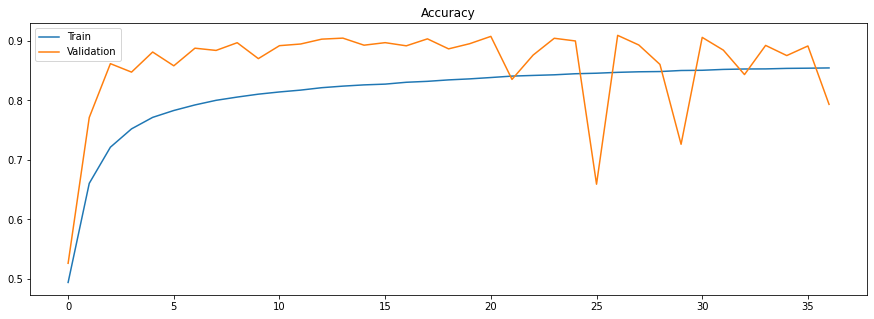

In [24]:
from pandas import read_csv
import matplotlib.pyplot as plt

plt.figure(figsize=(15,5))
plt.title("Loss")
plt.plot(history.history['loss'], label='Train')
plt.plot(history.history['val_loss'], label='Validation')
plt.legend()

plt.figure(figsize=(15,5))
plt.title("Accuracy")
plt.plot(history.history['accuracy'], label='Train')
plt.plot(history.history['val_accuracy'], label='Validation')
plt.legend()

<a name="5"></a>
# Evaluate best model

In [25]:
import tensorflow_addons as tfa
# load best model
trained_deep_model = tf.keras.models.load_model(join(config_model['checkpoint_path'] + config_model['network_name']))

<a name="5-1"></a>
### Train Dataset

In [26]:
test_performance = trained_deep_model.evaluate(train_dataset, verbose = 0)
y_train, y_pred = utils.generate_data(train_dataset, trained_deep_model)

  0% 0/1869 [00:00<?, ?it/s]

8/8 [==============================] - 0s 6ms/step


  0% 1/1869 [00:00<13:48,  2.25it/s]

8/8 [==============================] - 0s 2ms/step


  0% 2/1869 [00:00<09:42,  3.21it/s]

8/8 [==============================] - 0s 2ms/step


... (3,729 outputs left out)

8/8 [==============================] - 0s 2ms/step


100% 1868/1869 [07:05<00:00,  4.41it/s]

8/8 [==============================] - 0s 2ms/step


100% 1869/1869 [07:05<00:00,  4.39it/s]


In [27]:
config_model

{'checkpoint_path': 'trainings/',
 'database_path': '65HD_gestures_common',
 'training_name': 'EMG65_2D_CNN_multiclass_armband20260831_204013',
 'img_width': 16,
 'img_height': 8,
 'num_features': 256,
 'window_step': 12,
 'armband': False,
 'norm': 2,
 'model_output_mode': 'multiclass',
 'print_model': True,
 'network_name': 'EMG_65HDsEMG_2D_CNN_128f_128ch_SCE_normminmax_bychannel_adamW',
 'optimizer': 'adamW',
 'channels': 128,
 'early_stopping_patient': 10,
 'epochs': 200,
 'batch_size': 256,
 'lr': 0.01,
 'loss': 'SparceCatCE',
 'filter_divisor': 4,
 'num_classes': 12,
 'gesture_list': [0, 10, 8, 6, 4, 2, 13, 14, 15, 16, 61, 58]}

In [28]:
np.unique(y_train)

array([ 0.,  1.,  2.,  3.,  4.,  5.,  6.,  7.,  8.,  9., 10., 11.])

In [29]:
config_model['gesture_list']

[0, 10, 8, 6, 4, 2, 13, 14, 15, 16, 61, 58]

In [30]:
pr, re, f1, acc=metrics.model_metrics(config_model['gesture_list'] ,y_train, y_pred, Get_metrics=True) 

              precision    recall  f1-score   support

           0       0.97      0.97      0.97    127622
          10       0.97      0.93      0.95     30939
           8       0.92      0.91      0.91     31442
           6       0.91      0.96      0.94     30905
           4       0.96      0.96      0.96     32701
           2       0.98      0.95      0.97     33054
          13       0.97      0.99      0.98     31513
          14       0.95      0.93      0.94     32609
          15       0.93      0.98      0.96     31642
          16       0.97      0.95      0.96     31659
          61       0.93      0.93      0.93     31628
          58       0.99      0.98      0.98     32750

    accuracy                           0.96    478464
   macro avg       0.96      0.95      0.95    478464
weighted avg       0.96      0.96      0.96    478464



/usr/local/lib/python3.8/dist-packages/sklearn/metrics/_classification.py:1298: UserWarning: Note that pos_label (set to 'positive') is ignored when average != 'binary' (got 'macro'). You may use labels=[pos_label] to specify a single positive class.
  warnings.warn("Note that pos_label (set to %r) is ignored when "


Precision Score:  0.9550717538904882


/usr/local/lib/python3.8/dist-packages/sklearn/metrics/_classification.py:1298: UserWarning: Note that pos_label (set to 'positive') is ignored when average != 'binary' (got 'macro'). You may use labels=[pos_label] to specify a single positive class.
  warnings.warn("Note that pos_label (set to %r) is ignored when "


Recall Score:  0.9543833738926871
F1-Score:  0.9545556268056824
Accuracy:  0.9581431413857678


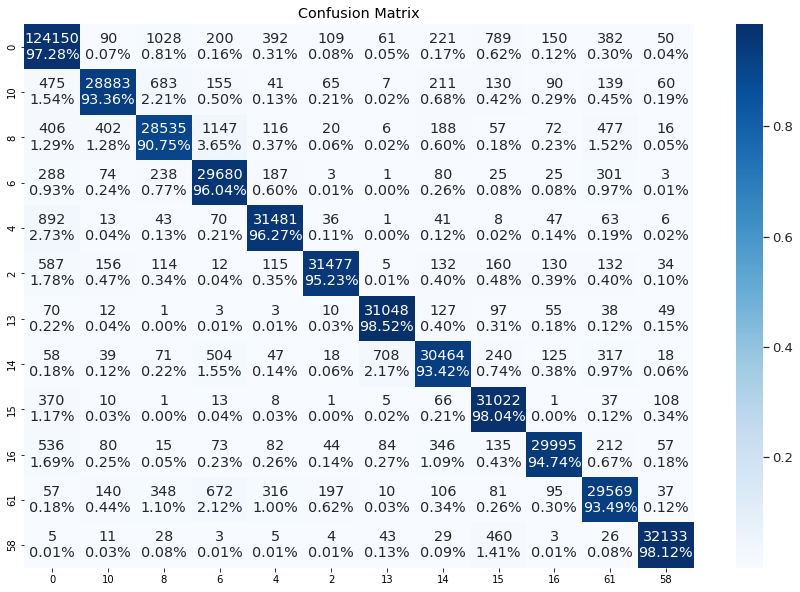

In [31]:
# available the train data 
cfm_deep_model=metrics.plot_confusion_matrix(config_model['gesture_list'], y_train, y_pred, Get_matrix=True)

<a name="5-2"></a>
### Test Dataset

In [32]:
test_performance = trained_deep_model.evaluate(test_dataset)
y_test, y_pred = utils.generate_data(test_dataset, trained_deep_model)

963/963 [==============================] - 90s 94ms/step - loss: 0.2900 - accuracy: 0.9158


  0% 0/963 [00:00<?, ?it/s]

8/8 [==============================] - 0s 2ms/step


  0% 1/963 [00:00<03:42,  4.33it/s]

8/8 [==============================] - 0s 2ms/step


  0% 2/963 [00:00<03:41,  4.33it/s]

... (1,918 outputs left out)

8/8 [==============================] - 0s 2ms/step


100% 962/963 [03:41<00:00,  4.45it/s]

8/8 [==============================] - 0s 2ms/step


100% 963/963 [03:42<00:00,  4.33it/s]


In [33]:
pr, re, f1, acc=metrics.model_metrics(config_model['gesture_list'] ,y_test, y_pred, Get_metrics=True) 

              precision    recall  f1-score   support

           0       0.97      0.96      0.96    128117
          10       0.87      0.81      0.84     10383
           8       0.86      0.76      0.81     10516
           6       0.77      0.88      0.82     10706
           4       0.85      0.91      0.88     11267
           2       0.92      0.85      0.88     11227
          13       0.96      0.93      0.94     10742
          14       0.85      0.89      0.87     10445
          15       0.82      0.92      0.87     11268
          16       0.91      0.87      0.89     11056
          61       0.77      0.86      0.82     10088
          58       0.88      0.89      0.89     10713

    accuracy                           0.92    246528
   macro avg       0.87      0.88      0.87    246528
weighted avg       0.92      0.92      0.92    246528

Precision Score:  0.8705242288189848


/usr/local/lib/python3.8/dist-packages/sklearn/metrics/_classification.py:1298: UserWarning: Note that pos_label (set to 'positive') is ignored when average != 'binary' (got 'macro'). You may use labels=[pos_label] to specify a single positive class.
  warnings.warn("Note that pos_label (set to %r) is ignored when "
/usr/local/lib/python3.8/dist-packages/sklearn/metrics/_classification.py:1298: UserWarning: Note that pos_label (set to 'positive') is ignored when average != 'binary' (got 'macro'). You may use labels=[pos_label] to specify a single positive class.
  warnings.warn("Note that pos_label (set to %r) is ignored when "


Recall Score:  0.8765760827959309
F1-Score:  0.8719711574908054
Accuracy:  0.9157986111111112


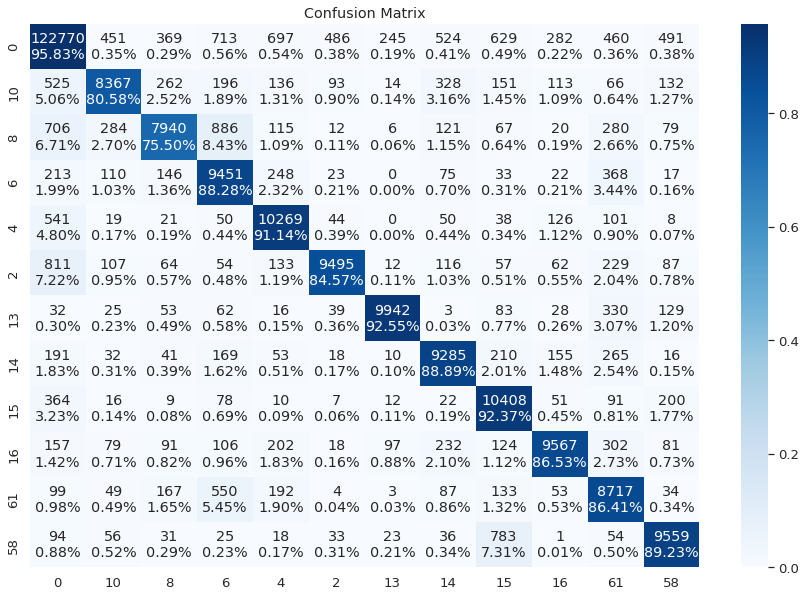

In [34]:
# available the test data 
cfm_deep_model=metrics.plot_confusion_matrix(config_model['gesture_list'], y_test, y_pred, Get_matrix=True)

#### Metrics with Average and std for each classes

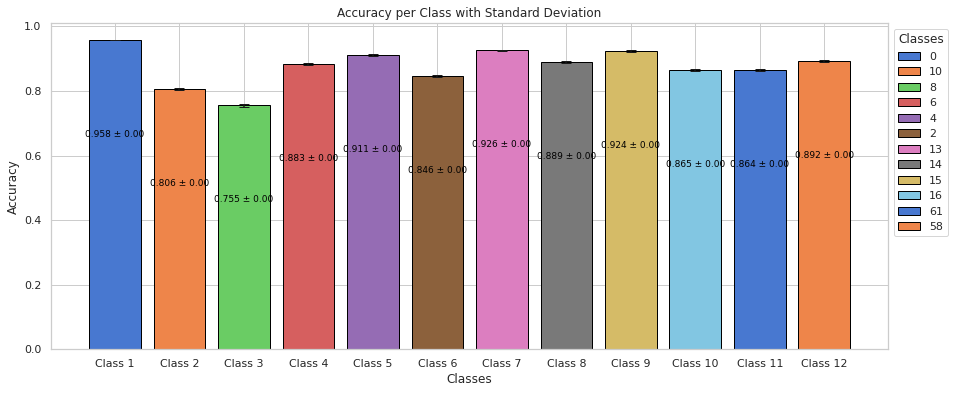

In [35]:
metrics.plot_metric_per_class(cfm_deep_model, config_model['gesture_list'], metric_name='Accuracy', method='per_class')

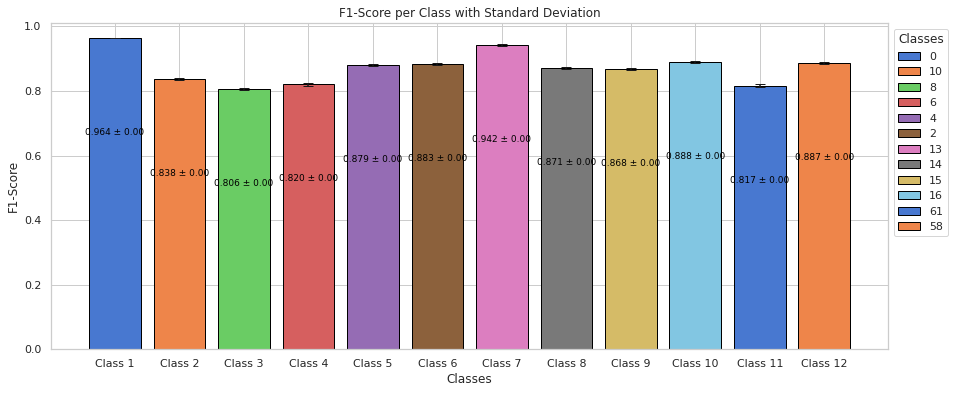

In [36]:
metrics.plot_metric_per_class(cfm_deep_model, config_model['gesture_list'], metric_name='F1-Score', method='per_class')

#### Mean and std for all Classes 

In [37]:
metrics_per_class,precision_list,recall_list,f1_score_list,accuracy_list=metrics.model_average_std_metrics(cf_matrix=cfm_deep_model, Get_metrics=True, Verbose=True) 

Precision Score: 0.8705±0.0622
Recall Score: 0.8766±0.0532
F1-Score: 0.872±0.0461
Accuracy: 0.8766±0.0532


In [38]:
metrics_average_and_std_df=pd.DataFrame(data=[precision_list,recall_list,f1_score_list,accuracy_list],
             index=['pr', 're', 'f1', 'acc'],
             columns=['Average','std'])
metrics_average_and_std_df

,Average,std
pr,0.870524,0.062231
re,0.876576,0.053189
f1,0.871971,0.046085
acc,0.876576,0.053189


## ROC

ROC AUC for Class 0: 0.96337
ROC AUC for Class 1: 0.90032
ROC AUC for Class 2: 0.87486
ROC AUC for Class 3: 0.93526
ROC AUC for Class 4: 0.95184
ROC AUC for Class 5: 0.92121
ROC AUC for Class 6: 0.96187
ROC AUC for Class 7: 0.94110
ROC AUC for Class 8: 0.95693
ROC AUC for Class 9: 0.93072
ROC AUC for Class 10: 0.92666
ROC AUC for Class 11: 0.94344


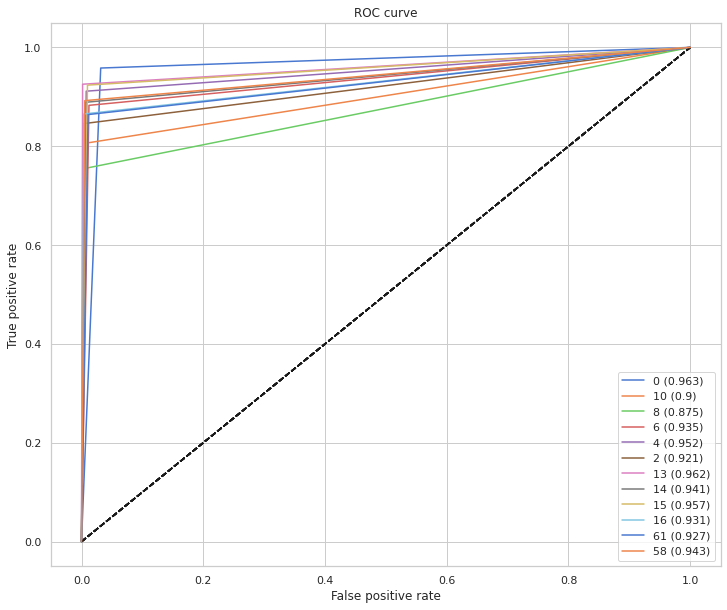

In [39]:
roc_score_per_class=metrics.get_roc_curve(config_model['gesture_list'], y_test, y_pred ,verbose=True)

In [40]:
# import mlflow_save_parameters_multiclass 

# mlflow_save_parameters_multiclass.save_data_in_mlflow("65HDsEMG_multiclass_armband", config_model, test_metric, data_processing.getProcessingNameList())

<a name="6"></a>
## Save the model in .H5 file

In [41]:
trained_deep_model.save(config_model['checkpoint_path'] +  config_model['network_name']+'/ResNet2D.h5')

In [42]:
config_model['checkpoint_path'] +  config_model['network_name']+'/ResNet2D.h5'

'trainings/EMG_65HDsEMG_2D_CNN_128f_128ch_SCE_normminmax_bychannel_adamW/ResNet2D.h5'